# Segmentación socio-sanitaria de los distritos de Madrid (caso 1.3) - cierre

Este notebook cierra el caso 1.3. Continúa el baseline exploratorio de `clustering_distritos.ipynb` (que queda como histórico) y hace tres cosas:

1. **Modelo final justificado**: la elección de algoritmo y de *k* se hace por ensayo y error documentado (k-means y jerárquico Ward con k = 2…8, y DBSCAN como tercer candidato que sugiere el enunciado).
2. **Robustez**: qué aguanta la partición y qué no (semillas, distritos atípicos, imputaciones, variables).
3. **Análisis socioeconómico completo**: cruces entre las variables para responder a la pregunta del caso: entender cómo se distribuye Madrid, si los distritos más vulnerables tienen tipologías de emergencia distintas y qué se asocia a los tiempos de respuesta.

Todo se calcula sobre los CSV ya limpios del repositorio (`data_clean/` y las tablas de esta carpeta); aquí no se vuelve a limpiar nada. Marco honesto: son 21 distritos, así que todo el análisis es **exploratorio**; no se afirma significación estadística ni causalidad.

## 1. Carga y comprobaciones

Se cargan las tablas del caso y las activaciones limpias, y se comprueba antes de nada que cada distrito es quien dice ser (21 filas, id único, nombre coherente entre la tabla real y la normalizada) y que el escalado 0-1 del CSV sigue correspondiendo a los valores reales. Si algo no cuadrara, el notebook pararía aquí en vez de analizar datos mal unidos.

Para los análisis por distrito solo valen las filas de los 21 distritos oficiales: se dejan fuera 567 activaciones sin distrito (`NO CONSTA`, decisión ya tomada en la limpieza) y 34 fuera del término municipal o en carreteras de circunvalación.

In [1]:
%matplotlib inline
import json, os, urllib.request, urllib.parse
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
raiz = carpeta if (carpeta / 'data_clean').is_dir() else carpeta / '..'
FIG = carpeta / 'graficos_cierre'
FIG.mkdir(exist_ok=True)

def guarda(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches='tight')
    print('guardado:', FIG / nombre)

df = pd.read_csv(carpeta / 'tabla_distritos.csv')
nrm = pd.read_csv(carpeta / 'tabla_distritos_norm.csv')

# No unir por posición sin comprobar la identidad de cada distrito.
for nombre, tabla in [('real', df), ('normalizada', nrm)]:
    assert len(tabla) == 21, f'Tabla {nombre}: se esperan 21 distritos'
    assert tabla['distrito_id'].notna().all() and tabla['distrito_id'].is_unique
assert set(df.distrito_id) == set(nrm.distrito_id)
nrm = nrm.set_index('distrito_id').loc[df.distrito_id].reset_index()
assert df['distrito'].equals(nrm['distrito'])

print('Entradas utilizadas (SHA-256):')
for archivo in ['tabla_distritos.csv', 'tabla_distritos_norm.csv']:
    print(' ', archivo, hashlib.sha256((carpeta / archivo).read_bytes()).hexdigest()[:16], '…')

act = pd.read_csv(raiz / 'data_clean' / 'activaciones_limpio.csv')
cat = pd.read_csv(raiz / 'data_clean' / 'tipos_emergencia_clean.csv')
n_total = len(act)
act = act[act.distrito.isin(df.distrito)].copy()
print(f'\nActivaciones: {n_total:,} en total; {n_total - len(act):,} fuera de los 21 distritos '
      f'(NO CONSTA / fuera de término / circunvalaciones) -> quedan {len(act):,}'.replace(',', '.'))

# Cada activación hereda la categoría corregida del catálogo de tipos (la columna
# "categoria" original era poco fiable; la limpieza ya dejó la versión corregida).
act = act.merge(cat[['codigo', 'categoria_correcta']],
                left_on='tipo_emergencia', right_on='codigo', how='left')
assert act['codigo'].notna().all(), 'Hay tipos de emergencia sin correspondencia en el catálogo'
act['hora'] = pd.to_datetime(act.hora_solicitud, format='%H:%M:%S', errors='coerce').dt.hour
print('Activaciones sin hora válida (cuentan para demanda, no para franjas):', int(act.hora.isna().sum()))
print('\nTablas cargadas y comprobadas:', df.shape, nrm.shape, act.shape)

Entradas utilizadas (SHA-256):
  tabla_distritos.csv 577306ee9131a89f …
  tabla_distritos_norm.csv 0e5a01aee3ee2a6c …



Activaciones: 146.567 en total; 601 fuera de los 21 distritos (NO CONSTA / fuera de término / circunvalaciones) -> quedan 145.966
Activaciones sin hora válida (cuentan para demanda, no para franjas): 1407

Tablas cargadas y comprobadas: (21, 22) (21, 22) (145966, 16)


## 2. Selección de variables para el clustering

Las mismas cuatro reglas del baseline, en este orden:

1. **Fuera las 3 columnas con datos desconocidos** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): tienen 7 celdas vacías (recursos etiquetados solo como "VALLECAS", que no se pueden repartir entre Puente y Villa de Vallecas sin inventar datos, y las camas del hospital de Arganzuela, que el dataset no trae). El criterio es **no imputar lo que no se sabe**: se excluyen del clustering y la oferta se analiza aparte con lo que sí se conoce (bases y activaciones). Detalle en `README_recursos_samur.md`.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debe decidir cómo se agrupan los distritos por su perfil socio-sanitario.
3. **Fuera las redundantes por construcción**: `poblacion` y `superficie_km2` (se prefiere densidad a tamaño absoluto) y `n_activaciones` (ya está en `activaciones_por_1000hab`, comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí** (|r| > 0,85): con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se queda una representante por grupo: `renta_media_hogar` (eje económico) y `pct_mayores_65` (eje edad), por ser las más directas de explicar.


#### Escalado de las variables para K-Means

Las variables seleccionadas mezclan euros, porcentajes, habitantes y minutos. K-Means asigna los grupos por distancias euclídeas: sin escalar, una variable con rango numérico mayor podría pesar mucho más en la distancia aunque no sea conceptualmente más importante. Se usa min-max por variable para llevar los valores a `[0, 1]` en `tabla_distritos_norm.csv`. Esto iguala los rangos, no decide pesos ni corrige redundancia; por eso la selección de variables correlacionadas se justifica aparte. En la celda siguiente se recalcula el min-max desde los datos reales, se compara con el CSV (tolerancia de 0,000051 por el redondeo a cuatro decimales) y se comprueba que la matriz `X` sea finita y esté en `[0, 1]` antes de entrar a K-Means.

El mapa de calor de abajo enseña **todas las combinaciones de variables** de la tabla, no solo las candidatas, para que la regla 4 se pueda auditar de un vistazo.

guardado: graficos_cierre/00_correlacion_todas_las_variables.png


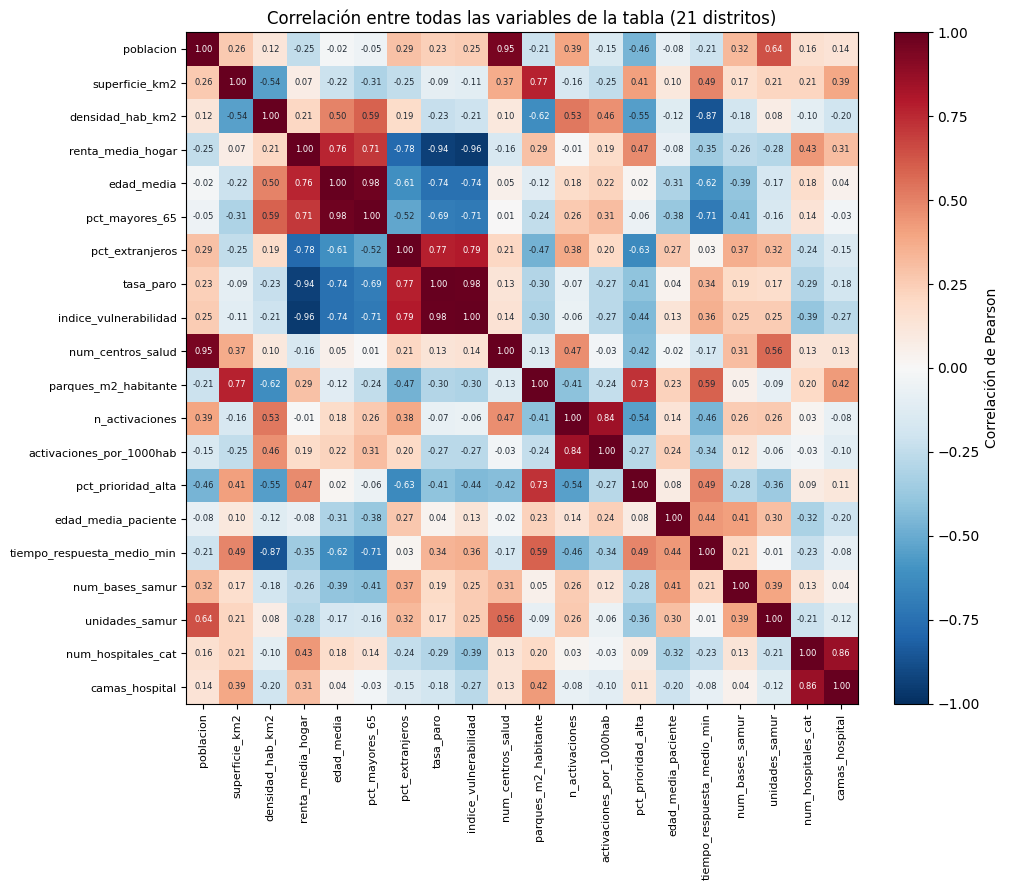

Pares de candidatas con |r| > 0,85 (regla 4):
  densidad_hab_km2 ~ tiempo_respuesta_medio_min: r = 0.87
  renta_media_hogar ~ tasa_paro: r = 0.94
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.96
  edad_media ~ pct_mayores_65: r = 0.98
  tasa_paro ~ indice_vulnerabilidad: r = 0.98

Variables finales del clustering (10):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - edad_media_paciente
 - tiempo_respuesta_medio_min

Matriz del clustering sin huecos: (21, 10)


In [2]:
numericas = [c for c in df.columns if c not in ('distrito_id', 'distrito')]
corr = df[numericas].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas))); ax.set_yticks(range(len(numericas)))
ax.set_xticklabels(numericas, rotation=90, fontsize=8)
ax.set_yticklabels(numericas, fontsize=8)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                color='white' if abs(v) > 0.6 else '#1f2933')
fig.colorbar(im, fraction=0.046, pad=0.04, label='Correlación de Pearson')
ax.set_title('Correlación entre todas las variables de la tabla (21 distritos)')
fig.tight_layout()
guarda(fig, '00_correlacion_todas_las_variables.png')
plt.show()

candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
cc = df[candidatas].corr().abs()
print('Pares de candidatas con |r| > 0,85 (regla 4):')
for i, a in enumerate(candidatas):
    for b in candidatas[i+1:]:
        if cc.loc[a, b] > 0.85:
            print(f'  {a} ~ {b}: r = {cc.loc[a, b]:.2f}')

variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

# Comprobar que el CSV normalizado sigue correspondiendo a los valores reales
# (el cruce guarda cuatro decimales: tolerancia de medio último decimal).
recalculada = (df[variables] - df[variables].min()) / (df[variables].max() - df[variables].min())
assert np.allclose(recalculada, nrm[variables], atol=0.000051, rtol=0), 'Escalado desactualizado'
X = nrm[variables].to_numpy()
assert np.isfinite(X).all() and ((X >= 0) & (X <= 1)).all().all()
print('\nMatriz del clustering sin huecos:', X.shape)

`renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). `densidad_hab_km2` y `tiempo_respuesta_medio_min` (r = -0,87) se conservan las dos porque miden cosas distintas del caso (geografía del distrito frente a servicio prestado); la sensibilidad a esta decisión se mide en la sección de robustez.

## 3. Elección de algoritmo y de k (ensayo y error)

Se prueban los dos algoritmos que sugiere el enunciado más el jerárquico:

- **K-means** con k = 2…8 (codo por inercia y silueta).
- **Jerárquico Ward** con k = 2…8 (silueta).
- **DBSCAN** con una rejilla de `eps` y `min_samples`. Con 21 puntos en 10 dimensiones o marca todo como ruido o forma grupos diminutos inestables que cambian por completo al mover `eps` 0,1: no da una segmentación defendible y se descarta.

Para elegir k se miran tres cosas: la silueta, que el codo deje de bajar fuerte y que los grupos sean accionables para el caso (perfiles distintos con los que planificar).

guardado: graficos_cierre/01_eleccion_de_k.png


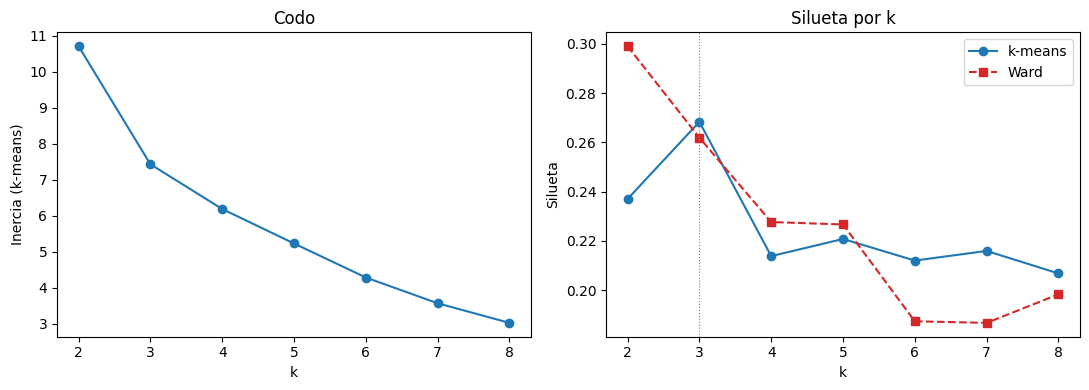

 k  inercia  silueta_kmeans  silueta_ward
 2     10.7           0.237         0.299
 3      7.4           0.268         0.262
 4      6.2           0.214         0.228
 5      5.2           0.221         0.227
 6      4.3           0.212         0.187
 7      3.6           0.216         0.187
 8      3.0           0.207         0.198

Prueba de DBSCAN (rejilla):
  eps=0.3, min_samples=2: 0 grupos, 21 puntos de ruido
  eps=0.3, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.4, min_samples=2: 2 grupos, 17 puntos de ruido
  eps=0.4, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.5, min_samples=2: 2 grupos, 16 puntos de ruido
  eps=0.5, min_samples=3: 1 grupos, 18 puntos de ruido
  eps=0.6, min_samples=2: 3 grupos, 8 puntos de ruido
  eps=0.6, min_samples=3: 2 grupos, 10 puntos de ruido
  eps=0.7, min_samples=2: 1 grupos, 5 puntos de ruido
  eps=0.7, min_samples=3: 1 grupos, 5 puntos de ruido

Qué hace cada k candidata (k-means):
  k=2:
   - Centro + Arganzuela + Retiro + Salaman

In [3]:
ks = range(2, 9)
inercias, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(ks), inercias, 'o-', color='#1f77b4')
ax1.set_xlabel('k'); ax1.set_ylabel('Inercia (k-means)'); ax1.set_title('Codo')
ax2.plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax2.plot(list(ks), sil_hc, 's--', label='Ward', color='#d62728')
ax2.axvline(3, color='grey', lw=0.8, ls=':')
ax2.set_xlabel('k'); ax2.set_ylabel('Silueta'); ax2.set_title('Silueta por k'); ax2.legend()
fig.tight_layout()
guarda(fig, '01_eleccion_de_k.png')
plt.show()

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 1),
                    'silueta_kmeans': np.round(sil_km, 3), 'silueta_ward': np.round(sil_hc, 3)}).to_string(index=False))

print('\nPrueba de DBSCAN (rejilla):')
for eps in (0.3, 0.4, 0.5, 0.6, 0.7):
    for ms in (2, 3):
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        print(f'  eps={eps}, min_samples={ms}: {len(set(lab) - {-1})} grupos, {(lab == -1).sum()} puntos de ruido')

print('\nQué hace cada k candidata (k-means):')
for k in (2, 3, 4):
    lab = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X).labels_
    grupos = [' + '.join(df.distrito.str.title()[lab == c]) for c in range(k)]
    print(f'  k={k}:')
    for g in grupos:
        print('   -', g)

**Lectura honesta.** El codo es gradual y la mejor silueta es ~0,30: los distritos no forman grupos muy compactos. Dentro de esa modestia:

- **k = 2** (Ward, silueta 0,299) solo separa "interior denso" de "anillo exterior": mezcla en un mismo saco distritos con perfiles sociales opuestos (Salamanca con Puente de Vallecas). Poco accionable.
- **k = 3** (k-means, silueta 0,268, segunda mejor de Ward) separa además los distritos acomodados de los densos y vulnerables: es la distinción que el caso pide explícitamente.
- **k = 4** baja la silueta (0,214) y solo parte por la mitad el grupo denso sin cambiar el mensaje.

Se elige **k-means con k = 3**, coherente con el baseline, por ser la opción más fina que mantiene una silueta competitiva y grupos interpretables.

## 4. Modelo final y perfiles

In [4]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

# Los nombres salen de la tabla de perfiles de abajo, no al revés.
nombres = {0: 'Denso y vulnerable', 1: 'Acomodado y envejecido', 2: 'Periférico y disperso'}
df['cluster_nombre'] = df.cluster.map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f'Cluster {c} - {nombres[c]} ({len(d)} distritos, '
          f'{int(d.n_activaciones.sum()):,} activaciones, {d.n_activaciones.sum() / df.n_activaciones.sum() * 100:.0f}% del total):'.replace(',', '.'))
    print('  ', ', '.join(d.distrito.str.title()))

cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA 21 DISTRITOS'] = df[cols_desc].mean().round(2)
print('\nPerfil de cada grupo (valores reales, no normalizados):')
print(perfil.to_string())

Cluster 0 - Denso y vulnerable (10 distritos. 89.341 activaciones. 61% del total):
   Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas
Cluster 1 - Acomodado y envejecido (6 distritos. 37.198 activaciones. 25% del total):
   Retiro, Salamanca, Chamartin, Chamberi, Moncloa-Aravaca, Moratalaz
Cluster 2 - Periférico y disperso (5 distritos. 19.427 activaciones. 13% del total):
   Fuencarral-El Pardo, Hortaleza, Villa De Vallecas, Vicalvaro, Barajas

Perfil de cada grupo (valores reales, no normalizados):
                        renta_media_hogar  tasa_paro  indice_vulnerabilidad  pct_mayores_65  pct_extranjeros  densidad_hab_km2  activaciones_por_1000hab  pct_prioridad_alta  edad_media_paciente  tiempo_respuesta_medio_min
cluster_nombre                                                                                                                                                                                        

guardado: graficos_cierre/02_perfil_de_los_grupos.png


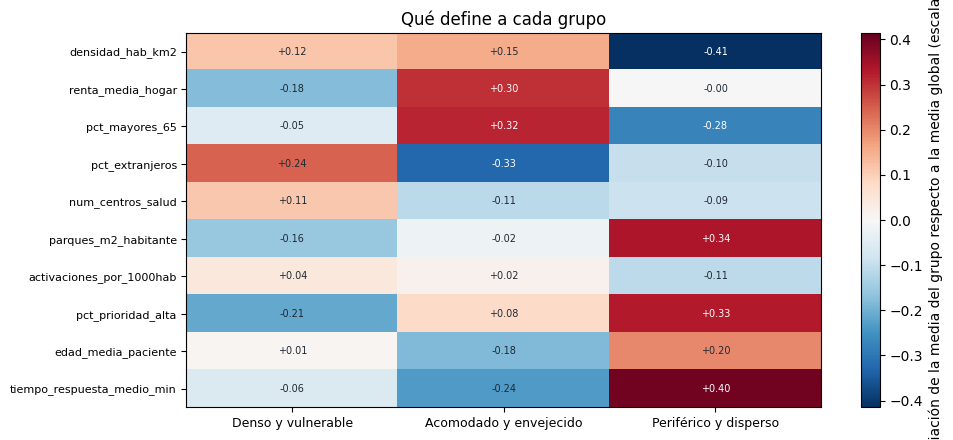

In [5]:
# Qué variable hace distinto a cada grupo: media normalizada del grupo menos media global
med_global = nrm[variables].mean()
dif = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean() - med_global

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(dif.T, cmap='RdBu_r', vmin=-np.abs(dif.to_numpy()).max(),
               vmax=np.abs(dif.to_numpy()).max(), aspect='auto')
fig.colorbar(im, label='Desviación de la media del grupo respecto a la media global (escala 0-1)')
ax.set_xticks(range(k_final)); ax.set_xticklabels([nombres[c] for c in range(k_final)], fontsize=9)
ax.set_yticks(range(len(variables))); ax.set_yticklabels(variables, fontsize=8)
for i in range(len(variables)):
    for j in range(k_final):
        ax.text(j, i, f'{dif.T.to_numpy()[i, j]:+.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(dif.T.to_numpy()[i, j]) > 0.25 else '#1f2933')
ax.set_title('Qué define a cada grupo')
fig.tight_layout()
guarda(fig, '02_perfil_de_los_grupos.png')
plt.show()

**Lectura de los tres perfiles:**

- **Denso y vulnerable** (10 distritos, 61% de las activaciones): renta baja, paro y vulnerabilidad altos, mucha densidad y muchos extranjeros. Es donde ocurre la mayor parte del servicio.
- **Acomodado y envejecido** (6 distritos): la renta más alta, más mayores de 65, más parques; respuesta más rápida.
- **Periférico y disperso** (5 distritos): muy poca densidad en distritos enormes, respuesta más lenta de media y la mayor proporción de prioridad alta.

## 5. El mapa de Madrid por grupos

guardado: graficos_cierre/03_mapa_grupos.png


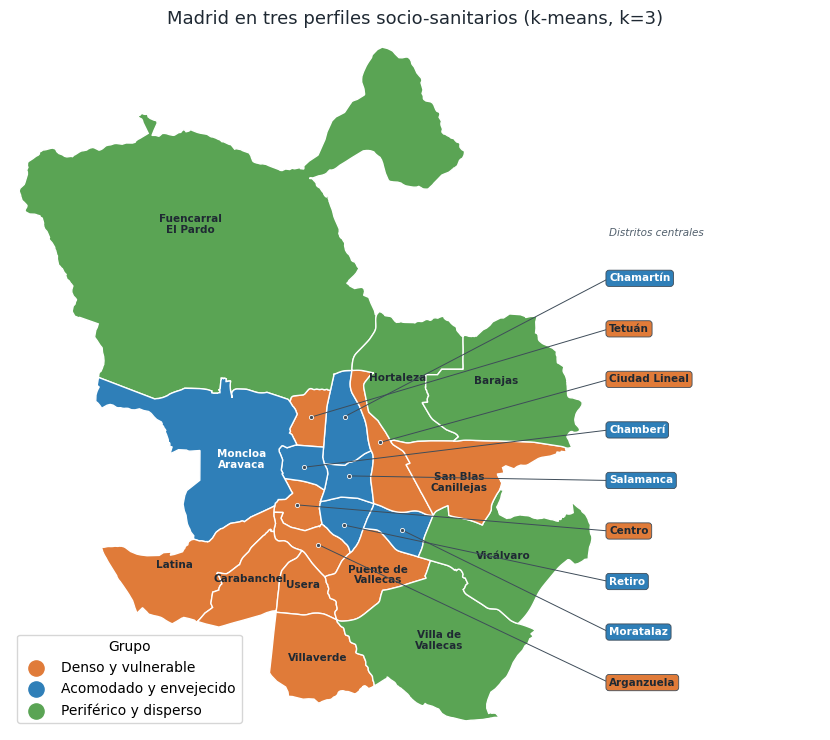

In [6]:
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS (ETRS89 / UTM 30N)
URL = ('https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?'
       + urllib.parse.urlencode({'where': '1=1', 'outFields': 'COD_DIS_TX,NOMBRE', 'outSR': 25830, 'f': 'geojson'}))
if not (carpeta / 'distritos_madrid.geojson').exists():
    urllib.request.urlretrieve(URL, carpeta / 'distritos_madrid.geojson')
g = json.load(open(carpeta / 'distritos_madrid.geojson'))
geo = {int(f['properties']['COD_DIS_TX']): (shape(f['geometry']), f['properties']['NOMBRE']) for f in g['features']}
assert sorted(geo) == sorted(df.distrito_id), 'Los códigos del mapa no coinciden con la tabla'

t = df.copy(); t['cod'] = t.distrito_id
t['nombre'] = t.cod.map(lambda c: geo[c][1])
short = {'Fuencarral - El Pardo': 'Fuencarral\nEl Pardo', 'Moncloa - Aravaca': 'Moncloa\nAravaca',
         'San Blas - Canillejas': 'San Blas\nCanillejas', 'Puente de Vallecas': 'Puente de\nVallecas',
         'Villa de Vallecas': 'Villa de\nVallecas', 'Ciudad Lineal': 'Ciudad\nLineal'}
t['lab'] = t.nombre.map(lambda n: short.get(n, n))
INK = '#1f2933'
CORE = [1, 2, 3, 4, 5, 6, 7, 14, 15]

def lum(c):
    r, g_, b = to_rgb(c); return .299 * r + .587 * g_ + .114 * b

def patch(poly, fc, lw=1.0, ec='white'):
    verts, codes = [], []
    for ring in [poly.exterior] + list(poly.interiors):
        xy = np.array(ring.coords)
        verts += list(xy); codes += [MPath.MOVETO] + [MPath.LINETO] * (len(xy) - 2) + [MPath.CLOSEPOLY]
    return PathPatch(MPath(verts, codes), fc=fc, ec=ec, lw=lw)

def draw(ax, colors, labels=None, fs=7.5, txtcol=None, ifs=7.5):
    for _, r in t.iterrows():
        ax.add_patch(patch(geo[r.cod][0], colors[r.cod]))
    b = [geo[c][0].bounds for c in geo]
    x0 = min(x[0] for x in b); y0 = min(x[1] for x in b)
    x1 = max(x[2] for x in b); y1 = max(x[3] for x in b); w = x1 - x0
    ax.set_xlim(x0 - 500, x1 + 0.40 * w); ax.set_ylim(y0 - 500, y1 + 500)
    ax.set_aspect('equal'); ax.axis('off')
    if labels is None:
        return
    for c in [c for c in geo if c not in CORE]:
        p = geo[c][0].representative_point()
        col = colors[c]
        ax.text(p.x, p.y, labels[c], ha='center', va='center', fontsize=fs,
                color=(txtcol[c] if txtcol else ('white' if lum(col) < .5 else INK)),
                fontweight='bold', linespacing=1.05)
    ys = {c: geo[c][0].representative_point() for c in CORE}
    order = sorted(CORE, key=lambda c: -ys[c].y)
    yc = np.mean([p.y for p in ys.values()]); span = (y1 - y0) * 0.075
    xs = x1 + 0.03 * w
    ax.text(xs, yc + (len(order) / 2) * span + span * .3, 'Distritos centrales',
            fontsize=ifs, color='#52606d', ha='left', va='bottom', style='italic')
    for k, c in enumerate(order):
        yy = yc + (len(order) / 2 - k - 0.5) * span
        p = ys[c]
        ax.plot([p.x, xs], [p.y, yy], color='#3e4c59', lw=.7, zorder=5, solid_capstyle='round')
        ax.plot(p.x, p.y, 'o', ms=3, color='#3e4c59', zorder=6, mec='white', mew=.6)
        col = colors[c]; tcol = ('white' if lum(col) < .5 else INK)
        ax.text(xs, yy, labels[c].replace('\n', ' '), ha='left', va='center', fontsize=ifs,
                fontweight='bold', color=tcol, zorder=7,
                bbox=dict(boxstyle='round,pad=0.3', fc=col, ec='#3e4c59', lw=.6))

COLORES_C = {0: '#e07b39', 1: '#2f7fb8', 2: '#5aa454'}
fig, ax = plt.subplots(figsize=(11, 7.5))
colores = {r.cod: COLORES_C[r.cluster] for _, r in t.iterrows()}
draw(ax, colores, labels=dict(zip(t.cod, t.lab)))
for c in range(3):
    ax.scatter([], [], color=COLORES_C[c], s=120, label=f'{nombres[c]}')
ax.legend(loc='lower left', fontsize=10, frameon=True, title='Grupo', title_fontsize=10)
ax.set_title('Madrid en tres perfiles socio-sanitarios (k-means, k=3)', fontsize=13, color=INK, pad=10)
fig.tight_layout()
guarda(fig, '03_mapa_grupos.png')
plt.show()

guardado: graficos_cierre/04_dendrograma_y_pca.png


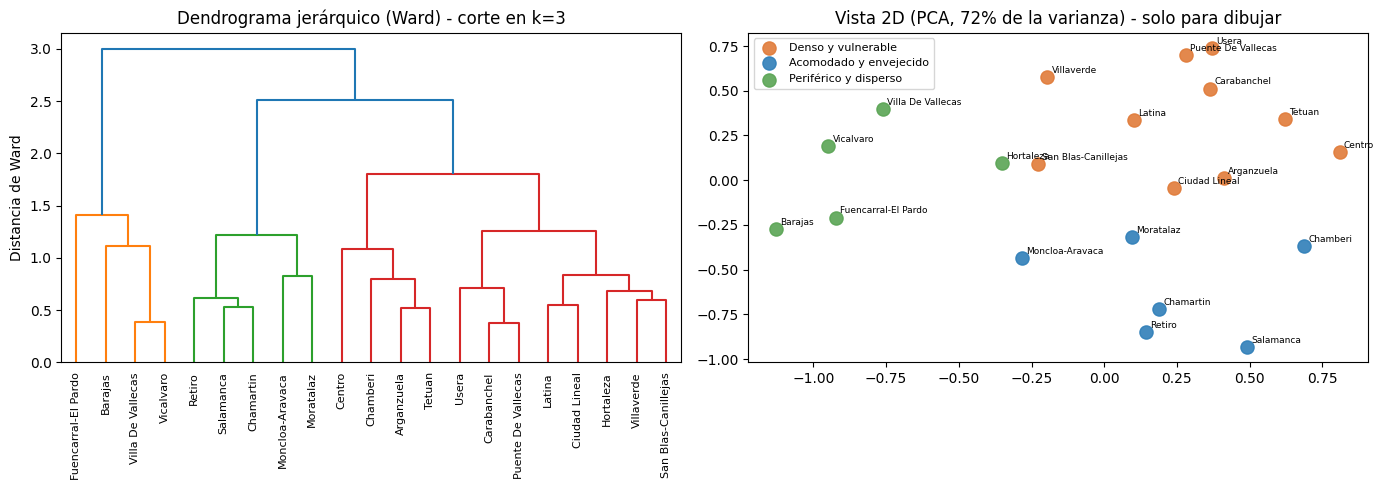

In [7]:
# Dendrograma Ward y vista 2D (PCA): dos formas de ver la misma estructura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
Z = linkage(X, method='ward')
dendrogram(Z, labels=df.distrito.str.title().tolist(), leaf_rotation=90, ax=ax1,
           color_threshold=Z[-(k_final - 1), 2], leaf_font_size=8)
ax1.set_title('Dendrograma jerárquico (Ward) - corte en k=3'); ax1.set_ylabel('Distancia de Ward')

pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    ax2.scatter(P[m, 0], P[m, 1], s=90, color=COLORES_C[c], label=nombres[c], alpha=0.9)
for i, r in df.iterrows():
    ax2.annotate(r.distrito.title(), (P[i, 0], P[i, 1]), fontsize=6.5,
                 xytext=(3, 3), textcoords='offset points')
ax2.set_title(f'Vista 2D (PCA, {pca.explained_variance_ratio_.sum() * 100:.0f}% de la varianza) - solo para dibujar')
ax2.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '04_dendrograma_y_pca.png')
plt.show()

## 6. Robustez: qué aguanta y qué no

Antes de sacar conclusiones, cuatro pruebas sobre la partición k = 3:

- **Otras 19 semillas** de k-means: ¿el resultado depende del azar del arranque?
- **Sin Centro**: distrito atípico (su tasa de activaciones por habitante casi triplica la del segundo).
- **Sin los 4 distritos con celdas imputadas** en las variables usadas (Retiro, Ciudad Lineal, Chamartín, San Blas-Canillejas).
- **Sin `renta_media_hogar` ni `pct_mayores_65`**: las dos variables con más peso social del modelo.
- **Ward en vez de k-means**: ¿otro algoritmo ve la misma estructura?

Se mide con ARI (1 = misma partición salvo el nombre de las etiquetas, 0 = azar).

In [8]:
res = {}
aris = []
for seed in range(1, 20):
    lab = KMeans(n_clusters=3, n_init=50, random_state=seed).fit(X).labels_
    aris.append(adjusted_rand_score(df.cluster, lab))
res['19 semillas distintas'] = f'ARI mín {min(aris):.2f} / mediano {np.median(aris):.2f}'

mA = df.distrito != 'CENTRO'
kmA = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mA.to_numpy()])
res['Sin Centro'] = f'ARI {adjusted_rand_score(df.loc[mA, "cluster"], kmA.labels_):.2f}'

afectados = ['RETIRO', 'CIUDAD LINEAL', 'CHAMARTIN', 'SAN BLAS-CANILLEJAS']
mB = ~df.distrito.isin(afectados)
kmB = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mB.to_numpy()])
res['Sin los 4 con imputaciones'] = f'ARI {adjusted_rand_score(df.loc[mB, "cluster"], kmB.labels_):.2f}'

vars_sin = [v for v in variables if v not in ('renta_media_hogar', 'pct_mayores_65')]
kmS = KMeans(n_clusters=3, n_init=50, random_state=42).fit(nrm[vars_sin].to_numpy())
res['Sin renta ni % >65'] = f'ARI {adjusted_rand_score(df.cluster, kmS.labels_):.2f}'

hc3 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X)
res['Ward en vez de k-means'] = f'ARI {adjusted_rand_score(df.cluster, hc3.labels_):.2f}'

for k, v in res.items():
    print(f'{k:32s} {v}')
print('\nWard mueve a Chamberí y Hortaleza al grupo denso y deja el periférico sin Hortaleza;')
print('los tres núcleos (vulnerable, acomodado, periférico) aparecen con cualquier método.')

19 semillas distintas            ARI mín 0.85 / mediano 0.85
Sin Centro                       ARI 1.00
Sin los 4 con imputaciones       ARI 1.00
Sin renta ni % >65               ARI 0.46
Ward en vez de k-means           ARI 0.69

Ward mueve a Chamberí y Hortaleza al grupo denso y deja el periférico sin Hortaleza;
los tres núcleos (vulnerable, acomodado, periférico) aparecen con cualquier método.


**Conclusión de la robustez:** la estructura de tres perfiles es estable (semillas, sin Centro, sin imputados: ARI ≈ 1) pero **no es una segmentación validada**: depende bastante de las dos variables sociales con más peso (sin renta ni % de mayores el ARI cae a 0,46) y la frontera entre el grupo denso y el acomodado se mueve según el algoritmo (ARI 0,69). Se presenta como lo que es: una segmentación exploratoria razonable y defendible, no una verdad estadística.

## 7. Cómo se distribuye Madrid: el análisis socioeconómico

Aquí está la respuesta a la pregunta del caso. Primero, el mapa de las variables clave.

guardado: graficos_cierre/05_mapas_variables.png


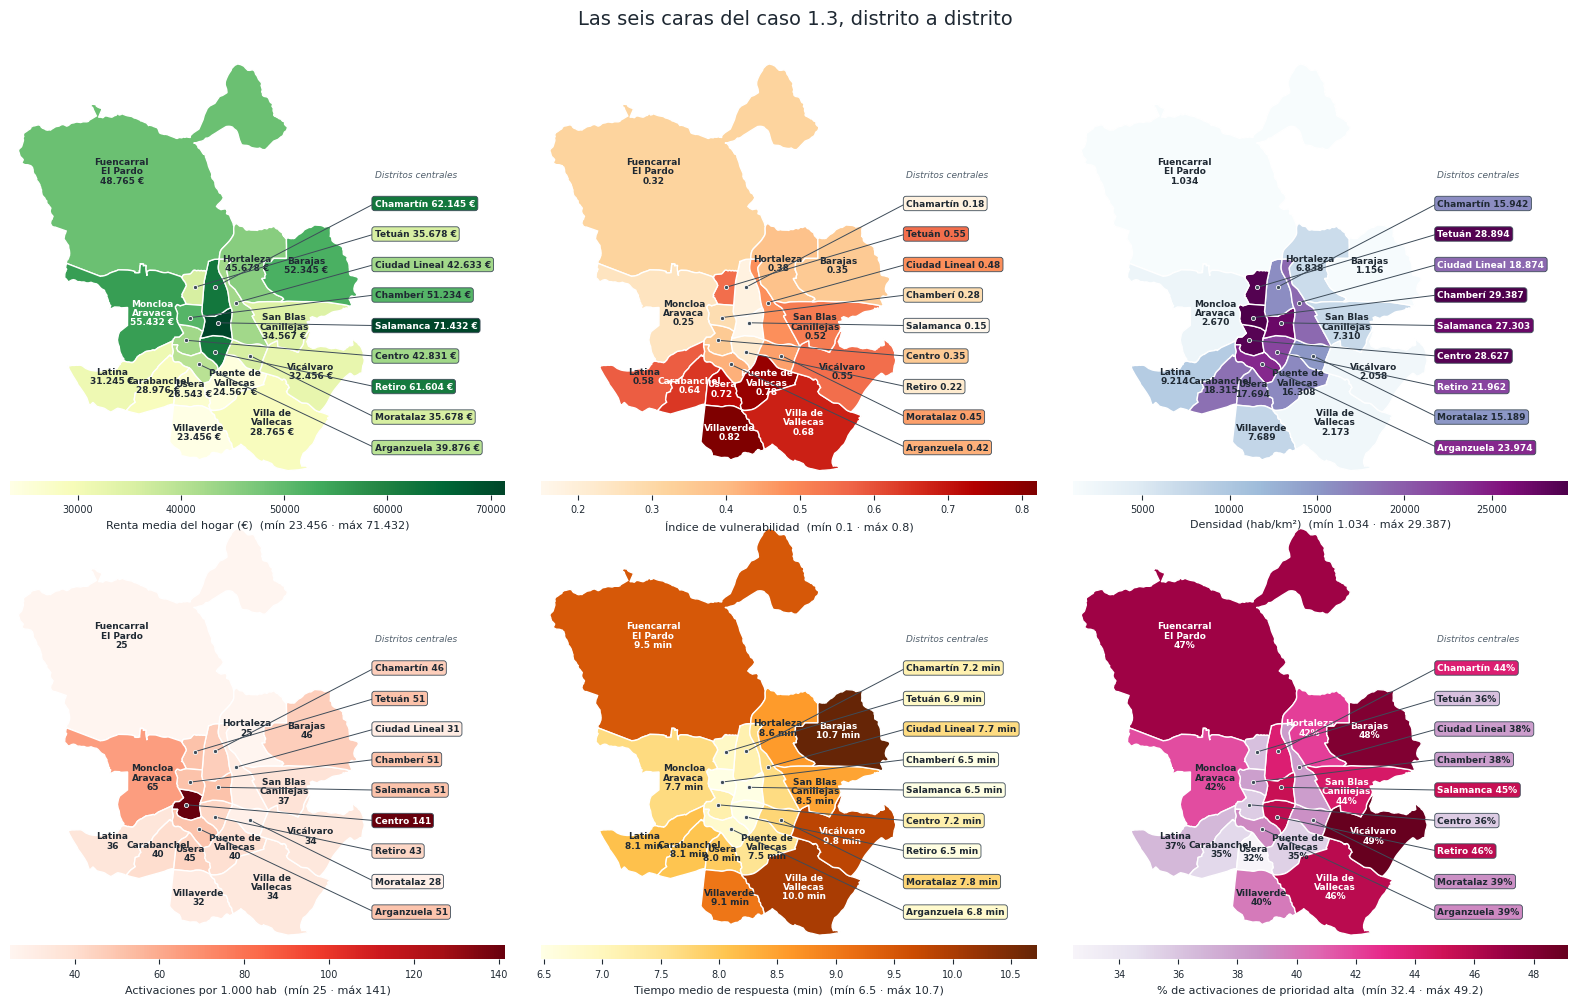

In [9]:
def choro(var, cmap, fmt):
    n = Normalize(t[var].min(), t[var].max())
    col = {r.cod: cmap(n(r[var])) for _, r in t.iterrows()}
    lab = {r.cod: r.lab + '\n' + fmt(r[var]) for _, r in t.iterrows()}
    tc = {c: ('white' if lum(col[c]) < .5 else INK) for c in col}
    return n, col, lab, tc

def cbar(fig, ax, n, cmap, label):
    sm = cm.ScalarMappable(norm=n, cmap=cmap)
    cb = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=.035, pad=.01, aspect=35)
    fm = (lambda x: f'{x:,.0f}'.replace(',', '.')) if n.vmax > 100 else (lambda x: f'{x:.1f}')
    cb.set_label(label + f'  (mín {fm(n.vmin)} · máx {fm(n.vmax)})', fontsize=8, color=INK)
    cb.ax.tick_params(labelsize=7, colors=INK); cb.outline.set_visible(False)

paneles = [
    ('renta_media_hogar', plt.get_cmap('YlGn'), lambda v: f'{v:,.0f} €'.replace(',', '.'), 'Renta media del hogar (€)'),
    ('indice_vulnerabilidad', plt.get_cmap('OrRd'), lambda v: f'{v:.2f}', 'Índice de vulnerabilidad'),
    ('densidad_hab_km2', plt.get_cmap('BuPu'), lambda v: f'{v:,.0f}'.replace(',', '.'), 'Densidad (hab/km²)'),
    ('activaciones_por_1000hab', plt.get_cmap('Reds'), lambda v: f'{v:.0f}', 'Activaciones por 1.000 hab'),
    ('tiempo_respuesta_medio_min', plt.get_cmap('YlOrBr'), lambda v: f'{v:.1f} min', 'Tiempo medio de respuesta (min)'),
    ('pct_prioridad_alta', plt.get_cmap('PuRd'), lambda v: f'{v:.0f}%', '% de activaciones de prioridad alta'),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (var, cmap, fmt, label) in zip(axes.flat, paneles):
    n, col, lab, tc = choro(var, cmap, fmt)
    draw(ax, col, labels=lab, txtcol=tc, fs=6.5, ifs=6.5)
    cbar(fig, ax, n, cmap, label)
fig.suptitle('Las seis caras del caso 1.3, distrito a distrito', fontsize=14, color=INK, y=1.00)
fig.tight_layout()
guarda(fig, '05_mapas_variables.png')
plt.show()

Los mapas ya cuentan la historia: la renta cae del noroeste al sureste, la vulnerabilidad hace justo el camino contrario, y la demanda por habitante se concentra en el centro. Los tiempos de respuesta crecen hacia el anillo exterior.

### 7.1 Lo que más y lo que menos se asocia al tiempo de respuesta

guardado: graficos_cierre/06_densidad_vs_tiempo.png


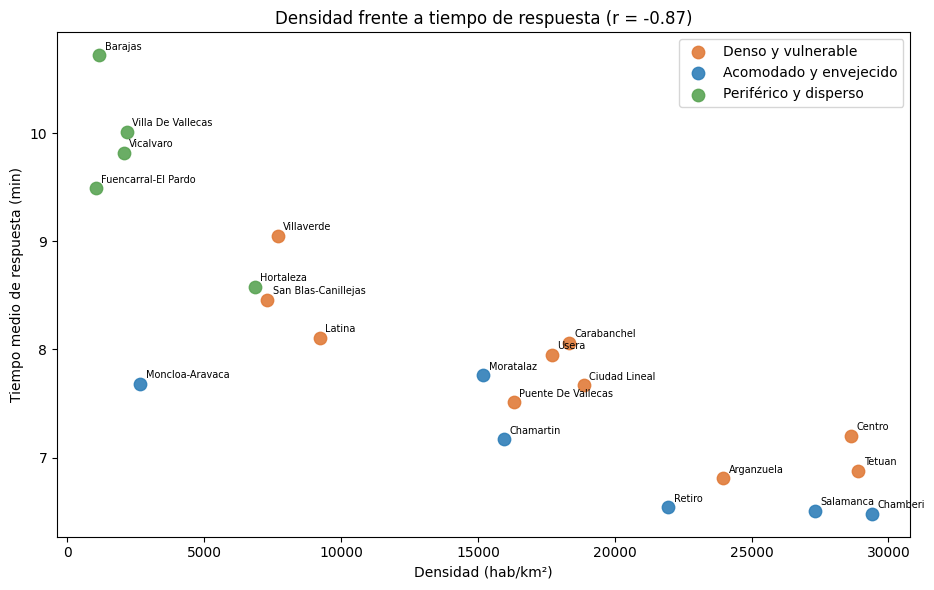

Correlación de cada variable con el tiempo medio de respuesta:
densidad_hab_km2           -0.87
pct_mayores_65             -0.71
edad_media                 -0.62
n_activaciones             -0.46
renta_media_hogar          -0.35
activaciones_por_1000hab   -0.34
num_hospitales_cat         -0.23
poblacion                  -0.21
num_centros_salud          -0.17
camas_hospital             -0.08
unidades_samur             -0.01
pct_extranjeros             0.03
num_bases_samur             0.21
tasa_paro                   0.34
indice_vulnerabilidad       0.36
edad_media_paciente         0.44
superficie_km2              0.49
pct_prioridad_alta          0.49
parques_m2_habitante        0.59


In [10]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.densidad_hab_km2, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
for _, r in df.iterrows():
    ax.annotate(r.distrito.title(), (r.densidad_hab_km2, r.tiempo_respuesta_medio_min),
                fontsize=7, xytext=(4, 4), textcoords='offset points')
r_val = df[['densidad_hab_km2', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax.set_xlabel('Densidad (hab/km²)'); ax.set_ylabel('Tiempo medio de respuesta (min)')
ax.set_title(f'Densidad frente a tiempo de respuesta (r = {r_val:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '06_densidad_vs_tiempo.png')
plt.show()

corr_t = df[numericas].corr().tiempo_respuesta_medio_min.drop('tiempo_respuesta_medio_min').sort_values()
print('Correlación de cada variable con el tiempo medio de respuesta:')
print(corr_t.round(2).to_string())

A más densidad, respuesta más rápida (r = -0,87): Chamberí es el más rápido (6,5 min) y Barajas el más lento (10,7). La superficie del distrito pesa más que cualquier variable social: es un problema de geografía, no de riqueza. Como densidad y tiempo están tan ligados, tener las dos en el clustering refuerza el eje "compacto frente a disperso" que separa al grupo periférico.

### 7.2 La demanda por habitante no es cosa de renta

guardado: graficos_cierre/07_renta_vs_activaciones.png


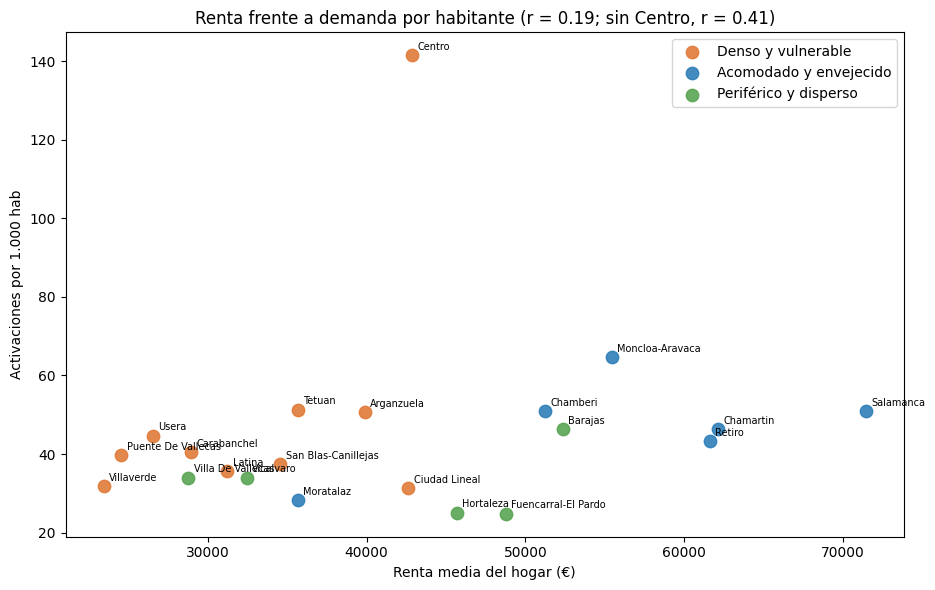

Centro: 141 activaciones/1.000 hab, frente a una media de 45


In [11]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.renta_media_hogar, d.activaciones_por_1000hab, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
for _, r in df.iterrows():
    ax.annotate(r.distrito.title(), (r.renta_media_hogar, r.activaciones_por_1000hab),
                fontsize=7, xytext=(4, 4), textcoords='offset points')
r_todos = df[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
sc = df[df.distrito != 'CENTRO']
r_sin = sc[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
ax.set_xlabel('Renta media del hogar (€)'); ax.set_ylabel('Activaciones por 1.000 hab')
ax.set_title(f'Renta frente a demanda por habitante (r = {r_todos:.2f}; sin Centro, r = {r_sin:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '07_renta_vs_activaciones.png')
plt.show()
print(f'Centro: {df.loc[df.distrito=="CENTRO","activaciones_por_1000hab"].iloc[0]:.0f} activaciones/1.000 hab, '
      f'frente a una media de {df.activaciones_por_1000hab.mean():.0f}')

Si algo, la demanda por habitante sube con la renta (r = 0,19; 0,41 sin Centro): no es un fenómeno de renta baja. Centro es un mundo aparte (141 activaciones por 1.000 hab, el triple de la media): la hipótesis es que recoge demanda de visitantes y ocio nocturno, no solo de vecinos, pero estos datos no permiten confirmarlo.

### 7.3 Los distritos vulnerables sí tienen una tipología de emergencia distinta

Esta es la pregunta central del enunciado. Se cruza cada activación con la categoría corregida del catálogo de tipos.

guardado: graficos_cierre/08_tipologia_por_grupo.png


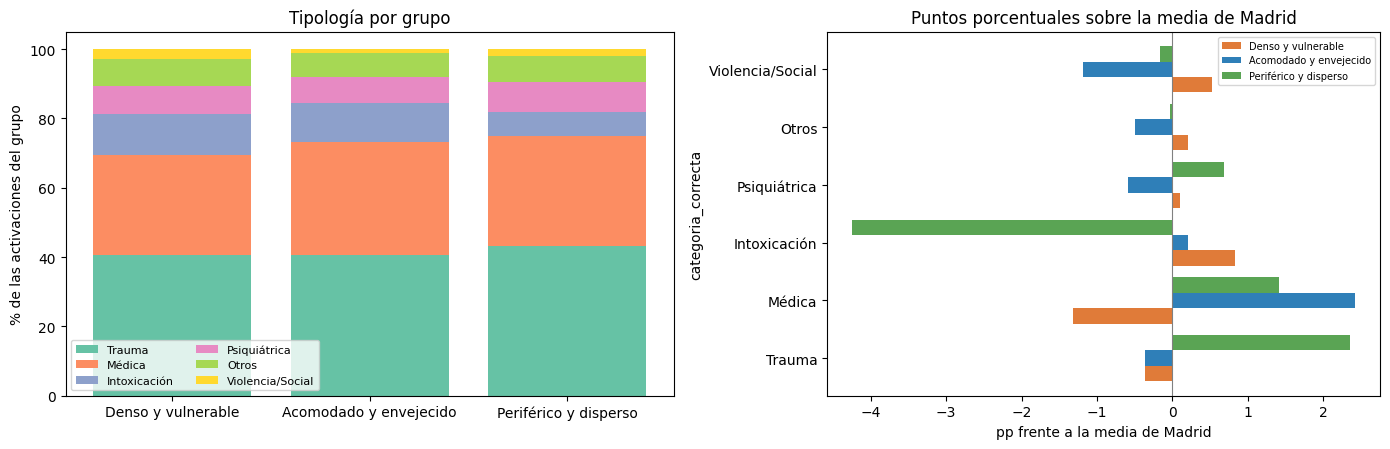

Mix por grupo (%), media de Madrid y diferencia en pp:
categoria_correcta      Trauma  Médica  Intoxicación  Psiquiátrica  Otros  Violencia/Social
Denso y vulnerable        40.5    29.0          11.9           8.1    7.8               2.7
Acomodado y envejecido    40.5    32.7          11.2           7.4    7.1               1.0
Periférico y disperso     43.2    31.7           6.8           8.7    7.6               2.0
MEDIA MADRID              40.9    30.3          11.0           8.0    7.6               2.2

Denso y vulnerable: Médica -1.3 pp; Intoxicación +0.8 pp; Violencia/Social +0.5 pp
Acomodado y envejecido: Médica +2.4 pp; Violencia/Social -1.2 pp; Psiquiátrica -0.6 pp
Periférico y disperso: Intoxicación -4.2 pp; Trauma +2.4 pp; Médica +1.4 pp

Violencia/Social: 2.7% en el grupo denso y vulnerable frente a 1.0% en el acomodado.


In [12]:
mix = pd.crosstab(act.cluster if 'cluster' in act else act.distrito.map(dict(zip(df.distrito, df.cluster))),
                  act.categoria_correcta, normalize='index') * 100
mix.index = [nombres[i] for i in mix.index]
orden = ['Trauma', 'Médica', 'Intoxicación', 'Psiquiátrica', 'Otros', 'Violencia/Social']
mix = mix[orden]
glob = (act.categoria_correcta.value_counts(normalize=True) * 100)[orden]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
bottom = np.zeros(3)
colcat = plt.get_cmap('Set2')
for i, categoriav in enumerate(orden):
    ax1.bar(mix.index, mix[categoriav], bottom=bottom, label=categoriav, color=colcat(i))
    bottom += mix[categoriav].to_numpy()
ax1.set_ylabel('% de las activaciones del grupo'); ax1.set_title('Tipología por grupo')
ax1.legend(fontsize=8, ncol=2)

dif_pp = (mix - glob).T
dif_pp.plot.barh(ax=ax2, color=[COLORES_C[0], COLORES_C[1], COLORES_C[2]], width=0.8)
ax2.axvline(0, color='grey', lw=0.8)
ax2.legend(fontsize=7)
ax2.set_title('Puntos porcentuales sobre la media de Madrid')
ax2.set_xlabel('pp frente a la media de Madrid')
fig.tight_layout()
guarda(fig, '08_tipologia_por_grupo.png')
plt.show()

print('Mix por grupo (%), media de Madrid y diferencia en pp:')
tabla_mix = mix.copy()
tabla_mix.loc['MEDIA MADRID'] = glob
print(tabla_mix.round(1).to_string())
print()
for nombre in mix.index:
    d = (mix.loc[nombre] - glob)
    top = d.reindex(d.abs().sort_values(ascending=False).index[:3])
    print(nombre + ': ' + '; '.join(f'{k} {v:+.1f} pp' for k, v in top.items()))
print(f"\nViolencia/Social: {mix.loc['Denso y vulnerable', 'Violencia/Social']:.1f}% en el grupo denso y vulnerable "
      f"frente a {mix.loc['Acomodado y envejecido', 'Violencia/Social']:.1f}% en el acomodado.")

guardado: graficos_cierre/09_tipos_concretos_por_grupo.png


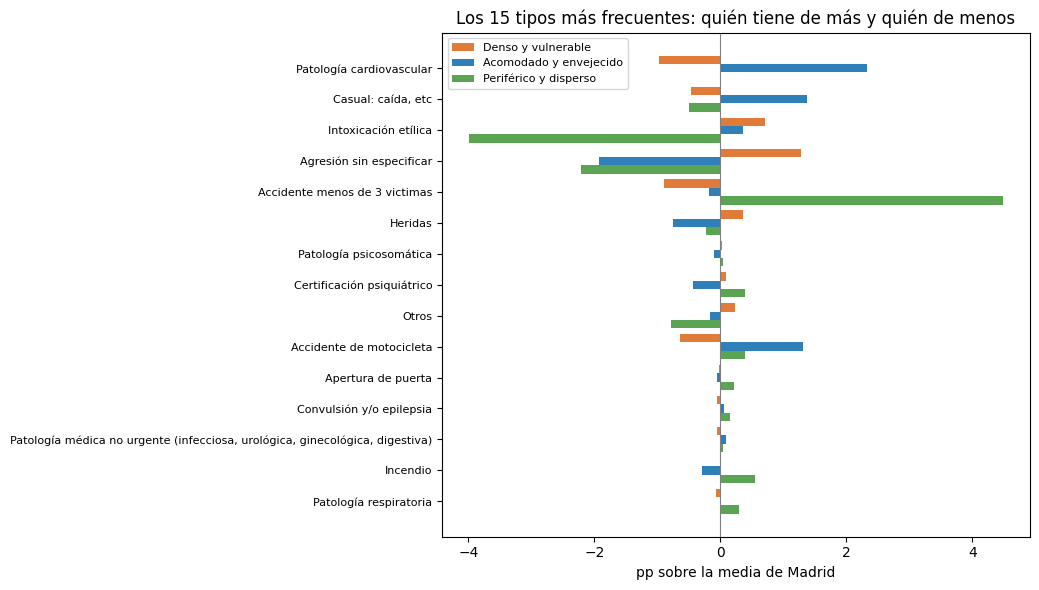

                                                                              Denso y vulnerable  Acomodado y envejecido  Periférico y disperso
tipo_emergencia                                                                                                                                
Patología cardiovascular                                                                    -1.0                     2.3                    0.0
Casual: caída, etc                                                                          -0.5                     1.4                   -0.5
Intoxicación etílica                                                                         0.7                     0.4                   -4.0
Agresión sin especificar                                                                     1.3                    -1.9                   -2.2
Accidente menos de 3 victimas                                                               -0.9                    -0.2                

In [13]:
# Tipos concretos que más distinguen a cada grupo (pp sobre la media)
top15 = act.tipo_emergencia.value_counts().head(15).index
gr = pd.crosstab(act.distrito.map(dict(zip(df.distrito, df.cluster))), act.tipo_emergencia,
                 normalize='index')[top15] * 100
gr.index = [nombres[i] for i in gr.index]
gl = act.tipo_emergencia.value_counts(normalize=True)[top15] * 100
dift = (gr - gl).T
fig, ax = plt.subplots(figsize=(10.5, 6))
y = np.arange(len(dift)); h = 0.27
for i, nombre in enumerate(dift.columns):
    ax.barh(y + (i - 1) * h, dift[nombre], height=h, color=COLORES_C[i], label=nombre)
ax.set_yticks(y); ax.set_yticklabels(dift.index, fontsize=8); ax.invert_yaxis()
ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('pp sobre la media de Madrid'); ax.set_title('Los 15 tipos más frecuentes: quién tiene de más y quién de menos')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '09_tipos_concretos_por_grupo.png')
plt.show()
print(dift.round(1).to_string())

Tres lecturas claras:

- El grupo **denso y vulnerable** concentra la violencia y lo social: agresiones por encima de la media y un 2,7% de activaciones de tipo Violencia/Social, casi el triple que el grupo acomodado (1,0%). Es la respuesta a la pregunta del enunciado: sí, los distritos más vulnerables presentan tipologías específicas.
- El grupo **periférico** destaca en accidentes de tráfico (+4,5 pp en "accidente de menos de 3 víctimas") y es el que menos intoxicaciones etílicas tiene (-4,0 pp): son distritos de carreteras y polígonos, no de ocio.
- El grupo **acomodado y envejecido** tiene más patología cardiovascular y caídas, coherente con su población mayor, y más accidentes de moto.

### 7.4 La noche madrileña se ve en los datos

guardado: graficos_cierre/10_ritmo_diario_e_intoxicacion.png


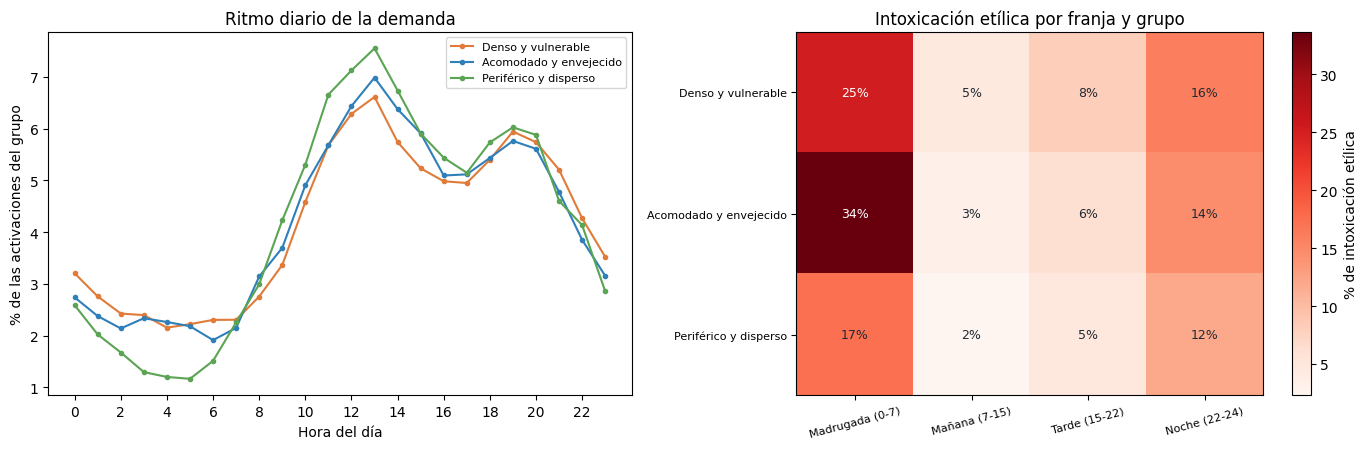

% de activaciones nocturnas (22-7 h), top 5:
distrito
CENTRO                32.2
CHAMBERI              29.1
TETUAN                25.9
USERA                 25.6
PUENTE DE VALLECAS    24.5


In [14]:
def franja(h):
    if pd.isna(h): return np.nan
    if 0 <= h < 7: return 'Madrugada (0-7)'
    if 7 <= h < 15: return 'Mañana (7-15)'
    if 15 <= h < 22: return 'Tarde (15-22)'
    return 'Noche (22-24)'
act['franja'] = act.hora.map(franja)
act['cluster_nombre'] = act.distrito.map(dict(zip(df.distrito, df.cluster_nombre)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
curvas = pd.crosstab(act.cluster_nombre, act.hora, normalize='index') * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax1.plot(range(24), curvas.loc[nombre, range(24)], marker='o', ms=3,
             color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax1.set_xlabel('Hora del día'); ax1.set_ylabel('% de las activaciones del grupo')
ax1.set_title('Ritmo diario de la demanda'); ax1.legend(fontsize=8); ax1.set_xticks(range(0, 24, 2))

intox = act[act.tipo_emergencia == 'Intoxicación etílica']
orden_f = ['Madrugada (0-7)', 'Mañana (7-15)', 'Tarde (15-22)', 'Noche (22-24)']
tot = pd.crosstab(act.cluster_nombre, act.franja)[orden_f]
ii = pd.crosstab(intox.cluster_nombre, intox.franja)[orden_f]
porc = (ii / tot * 100).loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
im = ax2.imshow(porc, cmap='Reds', aspect='auto')
ax2.set_xticks(range(4)); ax2.set_xticklabels(orden_f, fontsize=8, rotation=15)
ax2.set_yticks(range(3)); ax2.set_yticklabels(porc.index, fontsize=8)
for i in range(3):
    for j in range(4):
        ax2.text(j, i, f'{porc.to_numpy()[i, j]:.0f}%', ha='center', va='center', fontsize=9,
                 color='white' if porc.to_numpy()[i, j] > 20 else INK)
fig.colorbar(im, ax=ax2, label='% de intoxicación etílica')
ax2.set_title('Intoxicación etílica por franja y grupo')
fig.tight_layout()
guarda(fig, '10_ritmo_diario_e_intoxicacion.png')
plt.show()

noche = act.assign(n=act.hora.map(lambda h: pd.notna(h) and (h < 7 or h >= 22))).groupby('distrito').n.mean() * 100
print('% de activaciones nocturnas (22-7 h), top 5:')
print(noche.sort_values(ascending=False).head(5).round(1).to_string())

Los tres grupos comparten el pico de mediodía (13 h), pero las madrugadas los separan: el grupo periférico casi se apaga de 3 a 6 de la mañana mientras el centro sigue activo. De madrugada, **una de cada tres** activaciones del grupo acomodado es una intoxicación etílica (33,7%): es el mapa del ocio nocturno de Chamberí y Salamanca. Centro y Chamberí son los distritos más nocturnos (32% y 29% de su demanda entre las 22 y las 7 h).

### 7.5 La estacionalidad es común

guardado: graficos_cierre/11_estacionalidad.png


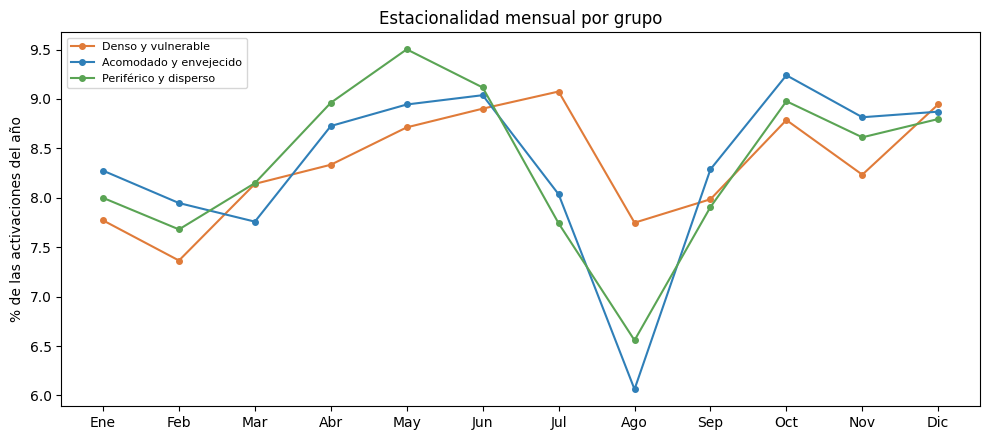

Media Madrid por mes (%):
mes
ENERO         7.9
FEBRERO       7.6
MARZO         8.0
ABRIL         8.5
MAYO          8.9
JUNIO         9.0
JULIO         8.6
AGOSTO        7.2
SEPTIEMBRE    8.1
OCTUBRE       8.9
NOVIEMBRE     8.4
DICIEMBRE     8.9


In [15]:
MESES = ['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'MAYO', 'JUNIO', 'JULIO', 'AGOSTO',
         'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE', 'DICIEMBRE']
fig, ax = plt.subplots(figsize=(10, 4.5))
mensual = pd.crosstab(act.cluster_nombre, act.mes)[MESES]
mensual = mensual.div(mensual.sum(axis=1), axis=0) * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax.plot(range(12), mensual.loc[nombre], marker='o', ms=4,
            color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_ylabel('% de las activaciones del año'); ax.set_title('Estacionalidad mensual por grupo')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '11_estacionalidad.png')
plt.show()
print('Media Madrid por mes (%):')
print((act.mes.value_counts()[MESES] / len(act) * 100).round(1).to_string())

Los tres grupos siguen el mismo calendario (picos en mayo-junio y octubre, valle en verano), pero con matices: el grupo acomodado se hunde en agosto (6,0% de su año, el valle más profundo: la ciudad acomodada se vacía) y el denso y vulnerable aguanta más el verano y pica en julio. Lo que de verdad separa a los perfiles, en cualquier caso, es la tipología y la noche, no el mes.

### 7.6 Prioridad alta y oferta frente a demanda

guardado: graficos_cierre/12_prioridad_y_oferta.png


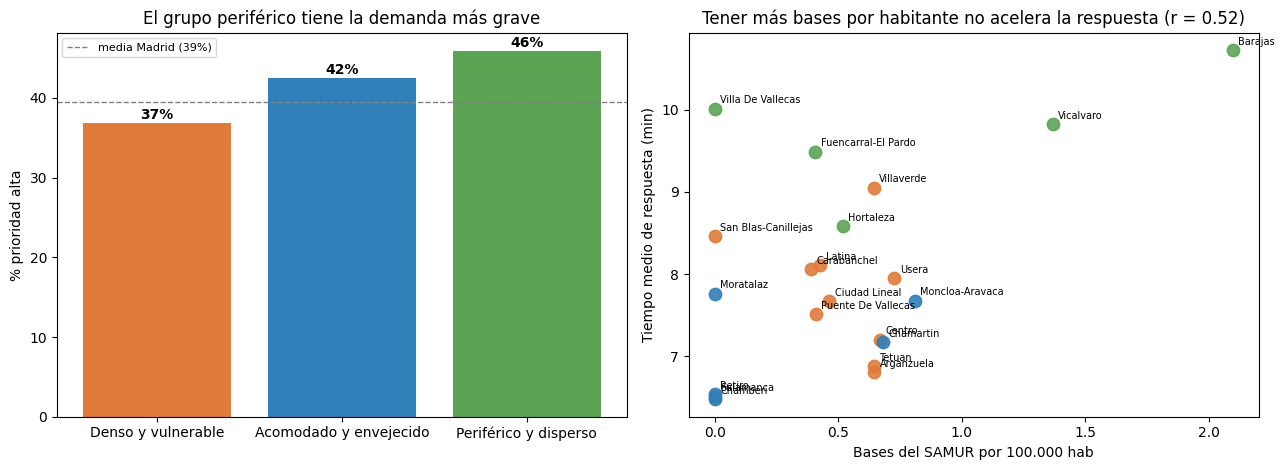

Activaciones anuales por base (media del grupo):
cluster_nombre
Acomodado y envejecido    7390.0
Denso y vulnerable        9251.0
Periférico y disperso     3906.0

Distritos sin base propia: Retiro, Salamanca, Chamberi, Moratalaz, Villa De Vallecas, San Blas-Canillejas


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
pa = act.assign(p=(act.prioridad == 'alta')).groupby('cluster_nombre').p.mean() * 100
pa = pa.loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
ax1.bar(pa.index, pa, color=[COLORES_C[i] for i in range(3)])
for i, v in enumerate(pa):
    ax1.text(i, v + 0.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=10)
ax1.axhline((act.prioridad == 'alta').mean() * 100, color='grey', ls='--', lw=1,
            label=f"media Madrid ({(act.prioridad == 'alta').mean() * 100:.0f}%)")
ax1.set_ylabel('% prioridad alta'); ax1.set_title('El grupo periférico tiene la demanda más grave')
ax1.legend(fontsize=8)

df['bases_por_100k'] = df.num_bases_samur / df.poblacion * 1e5
for c in range(3):
    d = df[df.cluster == c]
    ax2.scatter(d.bases_por_100k, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
                label=nombres[c], alpha=0.9)
for _, r in df.iterrows():
    ax2.annotate(r.distrito.title(), (r.bases_por_100k, r.tiempo_respuesta_medio_min),
                 fontsize=7, xytext=(4, 4), textcoords='offset points')
r_oferta = df[['bases_por_100k', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax2.set_xlabel('Bases del SAMUR por 100.000 hab'); ax2.set_ylabel('Tiempo medio de respuesta (min)')
ax2.set_title(f'Tener más bases por habitante no acelera la respuesta (r = {r_oferta:.2f})')
fig.tight_layout()
guarda(fig, '12_prioridad_y_oferta.png')
plt.show()

df['act_por_base'] = df.n_activaciones / df.num_bases_samur.replace(0, np.nan)
print('Activaciones anuales por base (media del grupo):')
print(df.groupby('cluster_nombre').act_por_base.mean().round(0).to_string())
print('\nDistritos sin base propia:', ', '.join(df[df.num_bases_samur == 0].distrito.str.title()))

Dos apuntes para planificar:

- El grupo periférico no solo es el más lento (9,5 min de media): también es el que tiene mayor proporción de prioridad alta (46% frente a 37% del denso). Los accidentes de tráfico pesan más en su mix, que suele ser demanda más grave.
- **Más bases por habitante no implica respuesta más rápida** (r = +0,52): Barajas es el distrito con más bases por habitante y también el más lento. Lo que manda es la dispersión geográfica, no el número de bases. Y la carga está muy desigualada: una base del grupo denso atiende de media ~9.300 activaciones al año, más del doble que una del periférico (~3.900). Ojo: las bases atienden también fuera de su distrito, así que esto es carga relativa, no cobertura real. Las 7 celdas de recursos desconocidas (Vallecas y camas de Arganzuela) impiden llevar este análisis a unidades y hospitales sin inventar datos; pendiente de que Bluetab confirme el reparto.

## 8. Conclusiones: la respuesta al caso

**Cómo se distribuye Madrid.** Los 21 distritos se agrupan de forma estable en tres perfiles socio-sanitarios:

1. **Denso y vulnerable** (Centro, Tetuán, Arganzuela, Carabanchel, Latina, Usera, Puente de Vallecas, Ciudad Lineal, San Blas-Canillejas, Villaverde): el 61% del servicio. Renta baja, paro y vulnerabilidad altos, máxima densidad. Es el distrito-tipo del SAMUR de día a día, y el que concentra la violencia y las agresiones (casi el triple de Violencia/Social que el acomodado).
2. **Acomodado y envejecido** (Salamanca, Chamberí, Chamartín, Retiro, Moncloa-Aravaca, Moratalaz): más mayores, más patología cardiovascular y caídas, respuesta más rápida y una madrugada dominada por el ocio (1 de cada 3 activaciones nocturnas es etílica).
3. **Periférico y disperso** (Fuencarral-El Pardo, Hortaleza, Vicálvaro, Villa de Vallecas, Barajas): distritos enormes con poca densidad, la respuesta más lenta, la demanda más grave en proporción y dominada por el tráfico.

**Lo que explica los tiempos** no es la riqueza ni el número de bases, sino la geografía: densidad y dispersión (r = -0,87 con la densidad; r = +0,52 entre bases por habitante y tiempo, en dirección "contraria").

**Limitaciones, dichas explícitamente:**

- 21 observaciones: segmentación exploratoria, sin significación estadística; sin causalidad (correlación no es causa).
- La partición depende de las variables sociales con más peso (sin renta ni % de mayores, ARI = 0,46) y la frontera denso/acomodado se mueve según el algoritmo (ARI = 0,69 con Ward).
- 7 celdas de recursos (unidades/hospitales/camas en los dos Vallecas y camas de Arganzuela) siguen desconocidas y fuera del modelo, pendientes de confirmación; no se han imputado para no inventar datos.
- Las activaciones no tienen día, solo mes y hora: no se puede analizar fin de semana frente a laborable.
- Centro probablemente mezcla demanda de no residentes (ocio y visitantes); hipótesis no confirmable con estos datos.

## 9. Reproducibilidad

- Entradas: `tabla_distritos.csv`, `tabla_distritos_norm.csv` (esta carpeta), `data_clean/activaciones_limpio.csv` y `data_clean/tipos_emergencia_clean.csv`. Nada se vuelve a limpiar aquí.
- Semilla fija (`random_state=42`) en todos los modelos; figuras guardadas en `graficos_cierre/`.
- El mapa usa los límites oficiales del Ayuntamiento de Madrid (`distritos_madrid.geojson`, se descarga si no está).
- Ejecutar de arriba abajo; los `assert` de la sección 1 paran el notebook si las tablas cambian.

## 10. Renta y tipos concretos de emergencia

Para comparar distritos de distinto tamaño, se calcula la tasa de cada tipo por 1.000 habitantes (`conteo del tipo / población × 1.000`), no el número bruto de activaciones. Se muestran Violencia/Social (categoría corregida del catálogo), Patología cardiovascular e Intoxicación etílica (tipos concretos). El gráfico compara estas tasas con `renta_media_hogar`; etiqueta los tres distritos con mayor tasa de cada tipo y muestra los 21 distritos. `r` es solo una correlación descriptiva. El denominador es la población residente, aunque las activaciones pueden incluir no residentes, especialmente en Centro. Hay 21 distritos: no se interpreta como prueba estadística ni causalidad.


guardado: graficos_cierre/13_renta_vs_tipos_emergencia.png
Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:
  Violencia/Social: r = -0.59
  Patología cardiovascular: r = 0.34
  Intoxicación etílica: r = 0.13


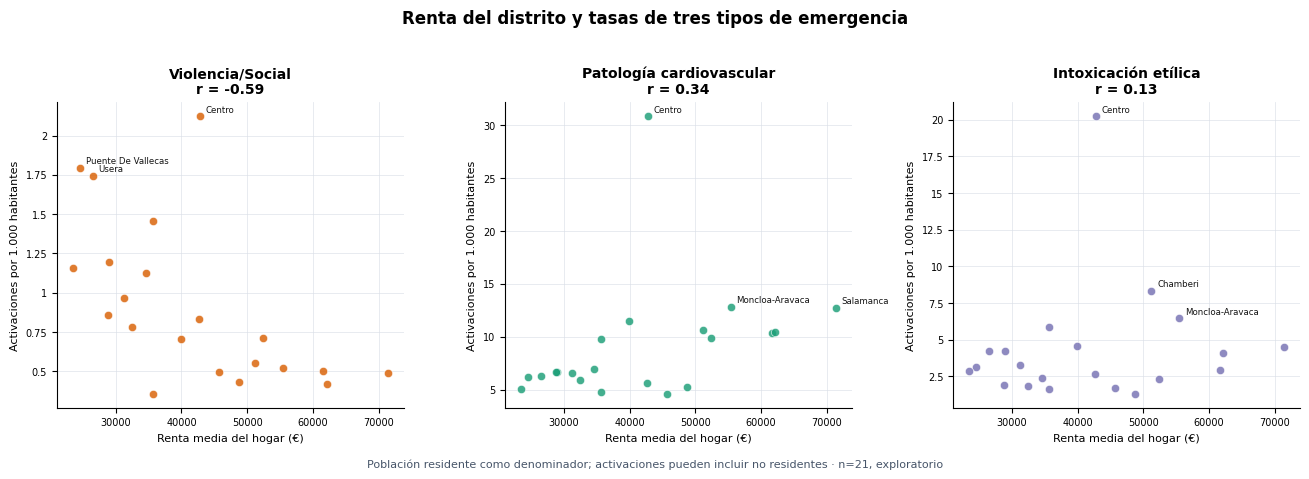

In [17]:
# Tasas distritales comparables: normalizar por población evita confundir volumen con tasa.
comparaciones = {
    'Violencia/Social': act.categoria_correcta.eq('Violencia/Social'),
    'Patología cardiovascular': act.tipo_emergencia.eq('Patología cardiovascular'),
    'Intoxicación etílica': act.tipo_emergencia.eq('Intoxicación etílica'),
}
base_renta = df.set_index('distrito')[['renta_media_hogar', 'poblacion']].copy()
conteos = pd.DataFrame({nombre: act.loc[mascara].groupby('distrito').size()
                        for nombre, mascara in comparaciones.items()})
conteos = conteos.reindex(base_renta.index, fill_value=0)
tasas = conteos.div(base_renta['poblacion'], axis=0) * 1000

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.4), sharex=True)
colores = ['#d95f02', '#1b9e77', '#7570b3']
correlaciones = []
for ax, (nombre, valores), color in zip(axes, tasas.items(), colores):
    x = base_renta['renta_media_hogar']
    r = pd.concat([x, valores.rename('tasa')], axis=1).corr().iloc[0, 1]
    correlaciones.append((nombre, r))
    ax.scatter(x, valores, s=35, color=color, alpha=.82, edgecolor='white', linewidth=.45, zorder=3)
    top = valores.nlargest(3).index
    for distrito in top:
        ax.annotate(distrito.title(), (x.loc[distrito], valores.loc[distrito]), fontsize=6.2,
                    alpha=.92, xytext=(4, 3), textcoords='offset points')
    ax.set_title(f'{nombre}\nr = {r:.2f}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Activaciones por 1.000 habitantes', fontsize=8)
    ax.grid(axis='both', color='#d9dee7', linewidth=.6, alpha=.7, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_xlabel('Renta media del hogar (€)', fontsize=8)
fig.suptitle('Renta del distrito y tasas de tres tipos de emergencia', fontsize=12, fontweight='bold', y=1.02)
fig.text(.5, -.02, 'Población residente como denominador; activaciones pueden incluir no residentes · n=21, exploratorio',
         ha='center', fontsize=8, color='#475569')
fig.tight_layout()
guarda(fig, '13_renta_vs_tipos_emergencia.png')
print('Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:')
for nombre, r in correlaciones:
    print(f'  {nombre}: r = {r:.2f}')
plt.show()
